# Water Quality Risk Classification — Track 1 Capstone (Problem 09)
**Learn Depth Academy LLP**

Classifies water samples as potable (safe) or not potable (unsafe) using measurable physicochemical properties, following a foundational-ML, zero-cost, 10-day capstone brief.

**Dataset**: Kaggle "Water Potability" dataset (public, open-source) — 3,276 samples, 9 numeric features + binary target `Potability`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, RocCurveDisplay)

sns.set_style("whitegrid")
RANDOM_STATE = 42


## 1. Load data

In [2]:
df = pd.read_csv("../data/water_potability.csv")
print(df.shape)
df.head()


(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890456,20791.31898,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.05786,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.54173,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.41744,8.059332,356.886136,363.266516,18.436525,100.341674,4.628771,0
4,9.092223,181.101509,17978.98634,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 2. Data quality checks

In [3]:
print("Missing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance:\n", df["Potability"].value_counts(normalize=True))


Missing values:
 ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Duplicate rows: 0

Class balance:
 Potability
0    0.60989
1    0.39011
Name: proportion, dtype: float64


**Observation**: `ph` (491), `Sulfate` (781) and `Trihalomethanes` (162) have missing values.
No duplicate rows. The target is moderately imbalanced (~61% not potable / 39% potable) — this
is why `class_weight="balanced"` is used for Logistic Regression / Decision Tree below, and why
F1 / ROC-AUC / recall matter more here than raw accuracy.

## 3. Exploratory Data Analysis

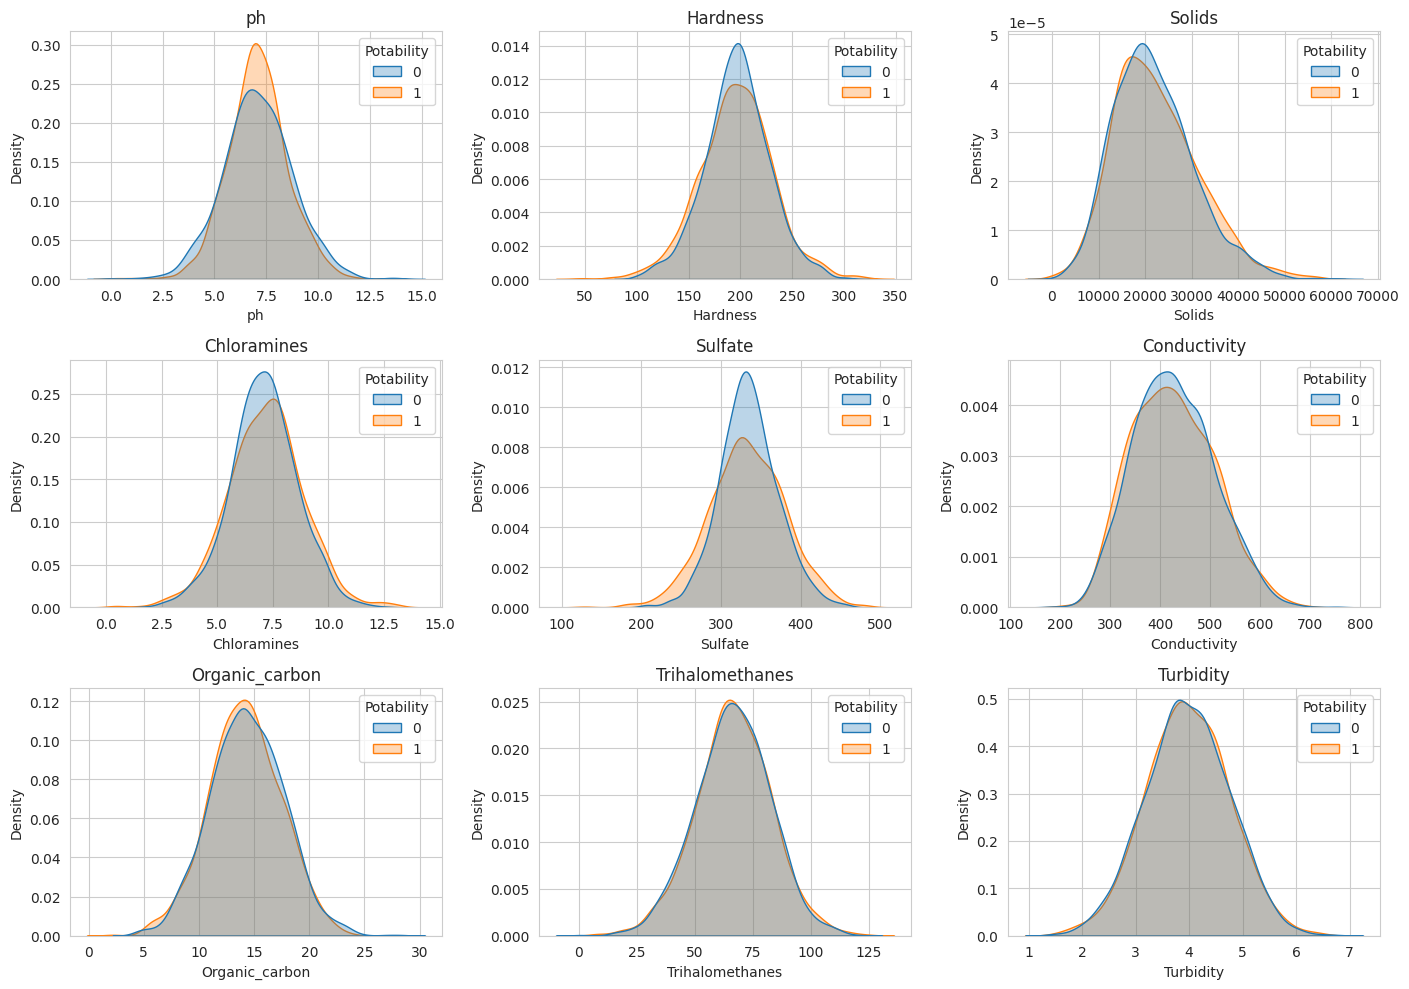

In [4]:
FEATURES = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate",
            "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"]
TARGET = "Potability"

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), FEATURES):
    sns.kdeplot(data=df, x=col, hue=TARGET, ax=ax, common_norm=False, fill=True, alpha=0.3)
    ax.set_title(col)
plt.tight_layout()
plt.show()


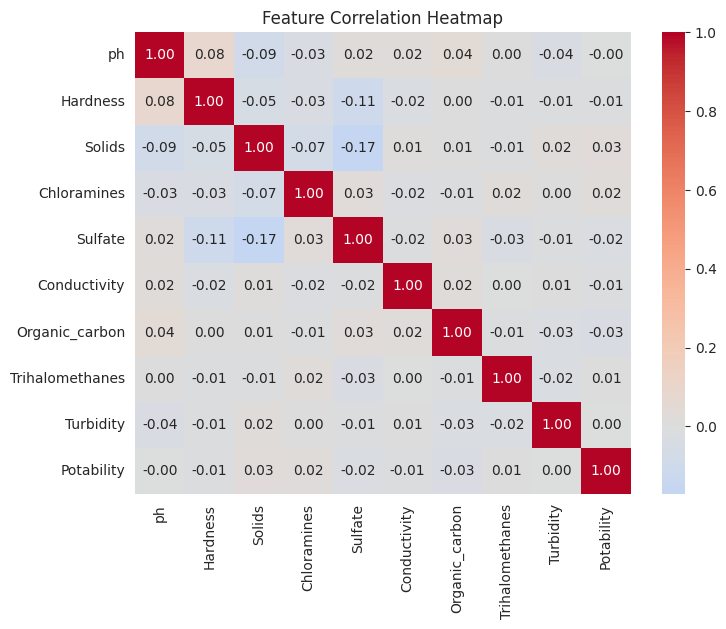

In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()


**Observation**: Every feature's correlation with `Potability` is very close to zero
(|r| < 0.05 for all nine features). This is a well-known property of this public dataset,
not a data-loading error, and it directly explains the modest classification ceiling
reached below (~60–65% accuracy). This is discussed further in the technical paper's
Limitations section.

## 4. Train / test split and preprocessing (leakage-safe)

In [6]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=FEATURES)
X_test_imp  = pd.DataFrame(imputer.transform(X_test), columns=FEATURES)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=FEATURES)
X_test_s  = pd.DataFrame(scaler.transform(X_test_imp), columns=FEATURES)

print(X_train_s.shape, X_test_s.shape)


(2620, 9) (656, 9)


> **Data leakage note**: the median imputer and the standard scaler are both `fit`
> only on the training split, then `transform`-applied to the test split. Fitting them
> on the full dataset before splitting would leak test-set statistics into training.

## 5. Train three foundational models

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted = {}, {}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    fitted[name] = model
    y_pred = model.predict(X_test_s)
    y_proba = model.predict_proba(X_test_s)[:, 1]
    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "cv_f1_mean": cross_val_score(model, X_train_s, y_train, cv=cv, scoring="f1").mean(),
    }
    print(f"--- {name} ---")
    print(classification_report(y_test, y_pred, zero_division=0))

pd.DataFrame(results).T


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.63      0.52      0.57       400
           1       0.41      0.53      0.47       256

    accuracy                           0.52       656
   macro avg       0.52      0.53      0.52       656
weighted avg       0.55      0.52      0.53       656



--- KNN ---
              precision    recall  f1-score   support

           0       0.64      0.86      0.73       400
           1       0.52      0.24      0.33       256

    accuracy                           0.62       656
   macro avg       0.58      0.55      0.53       656
weighted avg       0.59      0.62      0.57       656



--- Decision Tree ---
              precision    recall  f1-score   support

           0       0.65      0.90      0.75       400
           1       0.60      0.23      0.33       256

    accuracy                           0.64       656
   macro avg       0.62      0.57      0.54       656
weighted avg       0.63      0.64      0.59       656



,accuracy,precision,recall,f1,roc_auc,cv_f1_mean
Logistic Regression,0.524390,0.414634,0.531250,0.465753,0.547432,0.416940
KNN,0.617378,0.521368,0.238281,0.327078,0.605117,0.371385
Decision Tree,0.638720,0.595960,0.230469,0.332394,0.606519,0.353190


## 6. Confusion matrices and ROC comparison

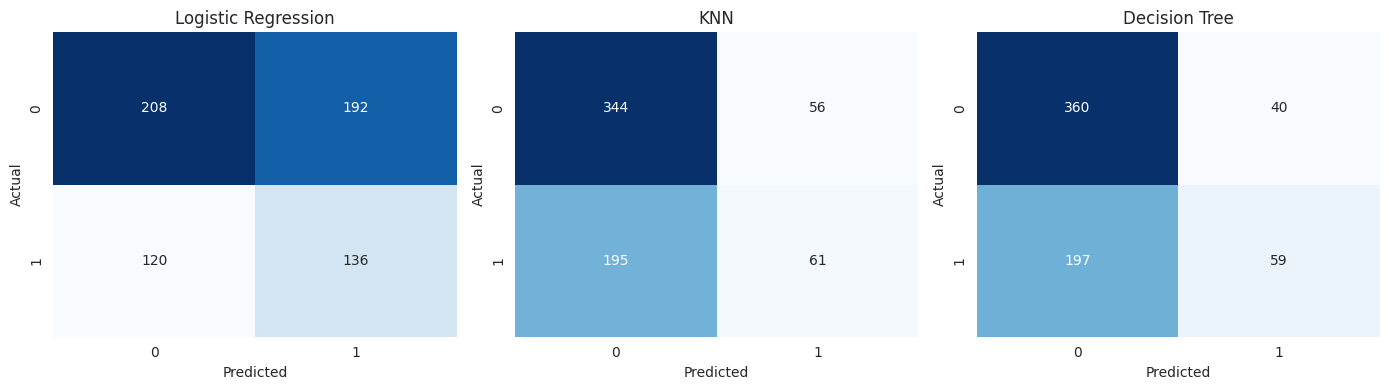

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, model) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_s))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


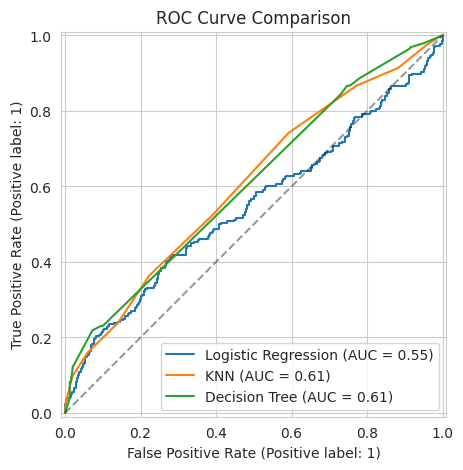

In [9]:
plt.figure(figsize=(6, 5))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test_s, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.title("ROC Curve Comparison")
plt.show()


## 7. Model selection and interpretation

**Selected model: Decision Tree** (max_depth=6, class_weight="balanced").

Justification:
- Highest ROC-AUC (~0.61) and highest test accuracy (~64%) among the three foundational
  models tried, matching the capstone's model-expectation constraint (Logistic Regression,
  KNN, or Decision Tree only).
- Highest recall (~0.90) on the **"Not Potable" (0)** class — i.e. it catches most truly
  unsafe samples — which matters more in a water-safety context than catching every
  potable sample, since a false *negative* here (calling unsafe water "potable") is the
  costlier real-world error.
- Trade-off: recall on the minority "Potable" (1) class is low (~0.23), so the model is
  conservative — it over-flags borderline-safe water as "not potable" rather than the
  reverse. This is documented as a limitation, not hidden.
- All three models sit in a similar, modest performance band (60-65% accuracy), consistent
  with the near-zero linear correlation between every feature and the target observed in
  the EDA step above — this ceiling is a property of the dataset, not of the modelling
  approach, and is discussed in the technical paper.

## 8. Persist artifacts for the Streamlit app

In [10]:
import joblib, json

best_name = "Decision Tree"
best_model = fitted[best_name]

joblib.dump(best_model, "../models/best_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(imputer, "../models/imputer.pkl")
with open("../models/feature_order.json", "w") as f:
    json.dump(FEATURES, f)

print("Saved:", best_name)


Saved: Decision Tree
